In [ ]:
from constant import openalex_dir
import polars as pl

authors_df = pl.read_ndjson(openalex_dir + 'works/author_id.jsonl.gz').filter(
    pl.col('author_id').list.len().is_between(1, 10)
)
doi_df = pl.read_ndjson(openalex_dir + 'works/doi.jsonl.gz').with_columns(
    pl.col("doi").str.replace("https://doi.org/", "").alias("doi")
)
authors_df.head()

work_id,author_id
str,list[str]
"""W4254804269""","[""A5064285042""]"
"""W4214486962""","[""A5064837938""]"
"""W1534361483""","[""A5105506287""]"
"""W3204041617""","[""A5101031318""]"
"""W4210515815""","[""A5046168805""]"


In [16]:
scopus_author = pl.read_parquet('data/journals/authids.parquet')
scopus_doi = pl.read_parquet('data/journals/doi.parquet')
scopus_author_name = pl.read_parquet('data/journals/authname.parquet')
scopus_author.head()

work_id,author_id
i64,list[i64]
107,"[7004442182, 7004442182, … 6602418637]"
110,"[7006050637, 6603697521, 6602703231]"
116,"[57218153744, 7402496690, 35351983100]"
117,"[7005148342, 7003508994]"
118,"[6603815313, 7004562485]"


In [ ]:
scopus_author_works = scopus_author.explode('author_id').group_by("author_id").agg(["work_id"])
scopus_author_works.write_parquet('data/journals/author_works.parquet')
scopus_author_works.head()

author_id,work_id
i64,list[i64]
35233311500,"[55849146354, 61849108681, … 85185397586]"
7003367364,[36806089]
57217451704,"[2442508686, 2442508686, 2442508686]"
35278292100,[67649444229]
56308458200,"[84938783018, 84944704736, … 85130087418]"


In [119]:
scopus_author_works.write_parquet('data/journals/author_works.parquet')

In [45]:
scopus_works_df = scopus_author.join(
    scopus_doi,
    on='work_id'
)
scopus_works_df.head()

work_id,author_id,doi
i64,list[i64],str
107,"[7004442182, 7004442182, … 6602418637]","""10.1175/1520-0442(1997)010<218…"
110,"[7006050637, 6603697521, 6602703231]","""10.1063/1.1285965"""
116,"[57218153744, 7402496690, 35351983100]","""10.1103/PhysRevE.56.623"""
117,"[7005148342, 7003508994]","""10.1086/304826"""
118,"[6603815313, 7004562485]","""10.1002/(SICI)1521-4109(199907…"


In [ ]:
oa = pl.concat([
    pl.read_parquet("./data/biorxiv/biorxiv_citation_detail.parquet").with_columns(pl.lit("biorxiv").alias("server")),
    pl.read_parquet("./data/arxiv/arxiv_citation_detail.parquet").with_columns(pl.lit("arxiv").alias("server"))
]).join(
    authors_df,
    on="work_id",
    how="right"
)

In [27]:
oa_ = oa.explode('author_id').with_columns(
    pl.count("work_id").over("author_id").alias("works_count"),
).filter(
    pl.col("works_count") > 2
)

oa_.head()

work_id,publication_year,primary_cat,primary_field,c5,server,author_id,doi,works_count
str,i32,str,str,i32,str,str,str,u32
"""W2564915103""",2016,"""cond-mat.mes-hall""","""cond-mat""",1,"""arxiv""","""A5057004545""","""10.48550/arxiv.1612.03850""",3
"""W2564915103""",2016,"""cond-mat.mes-hall""","""cond-mat""",1,"""arxiv""","""A5049741006""","""10.48550/arxiv.1612.03850""",13
"""W2564915103""",2016,"""cond-mat.mes-hall""","""cond-mat""",1,"""arxiv""","""A5065567071""","""10.48550/arxiv.1612.03850""",17
"""W2564915103""",2016,"""cond-mat.mes-hall""","""cond-mat""",1,"""arxiv""","""A5026215124""","""10.48550/arxiv.1612.03850""",32
"""W2564915103""",2016,"""cond-mat.mes-hall""","""cond-mat""",1,"""arxiv""","""A5020663425""","""10.48550/arxiv.1612.03850""",9


In [46]:
preprint_author_works = (
    authors_df.explode("author_id").filter(
        pl.col("author_id").is_in(oa_.get_column("author_id").to_numpy()),
        ~(pl.col("work_id").is_in(oa_.get_column("work_id").to_numpy()))
    ).group_by("work_id").agg(["author_id"])
    .join(
        doi_df,
        on="work_id",
        how="inner"
    )
)
print(preprint_author_works.height)
preprint_author_works.head()

16529094


work_id,author_id,doi
str,list[str],str
"""W2279720585""","[""A5020021560""]","""10.3929/ethz-a-006499300"""
"""W185088531""","[""A5012745879""]","""10.1007/978-1-349-09318-2"""
"""W2975885102""","[""A5028696052"", ""A5059713279""]","""10.2210/pdb1dgb/pdb"""
"""W2285803381""","[""A5078570777""]","""10.5948/9781614441168.048"""
"""W2498455391""","[""A5037457090""]","""10.1002/9780470612491.ch1"""


In [32]:
print(oa_.height)
print(oa_.unique("author_id").height)
print(oa.explode("author_id").unique("author_id").height)

1797378
258138
880180


# assignment probability

In [ ]:
oa_.head()

work_id,publication_year,primary_cat,primary_field,c5,server,author_id,doi,works_count
str,i32,str,str,i32,str,str,str,u32
"""W2564915103""",2016,"""cond-mat.mes-hall""","""cond-mat""",1,"""arxiv""","""A5057004545""","""10.48550/arxiv.1612.03850""",3
"""W2564915103""",2016,"""cond-mat.mes-hall""","""cond-mat""",1,"""arxiv""","""A5049741006""","""10.48550/arxiv.1612.03850""",13
"""W2564915103""",2016,"""cond-mat.mes-hall""","""cond-mat""",1,"""arxiv""","""A5065567071""","""10.48550/arxiv.1612.03850""",17
"""W2564915103""",2016,"""cond-mat.mes-hall""","""cond-mat""",1,"""arxiv""","""A5026215124""","""10.48550/arxiv.1612.03850""",32
"""W2564915103""",2016,"""cond-mat.mes-hall""","""cond-mat""",1,"""arxiv""","""A5020663425""","""10.48550/arxiv.1612.03850""",9


In [ ]:
# preprint_author_works

work_id,author_id,doi
str,list[str],str
"""W2279720585""","[""A5020021560""]","""10.3929/ethz-a-006499300"""
"""W185088531""","[""A5012745879""]","""10.1007/978-1-349-09318-2"""
"""W2975885102""","[""A5028696052"", ""A5059713279""]","""10.2210/pdb1dgb/pdb"""
"""W2285803381""","[""A5078570777""]","""10.5948/9781614441168.048"""
"""W2498455391""","[""A5037457090""]","""10.1002/9780470612491.ch1"""
…,…,…
"""W4408162163""","[""A5052507508"", ""A5027264859""]","""10.1111/nph.70045"""
"""W4408162181""","[""A5052408115""]","""10.1002/vms3.70278"""
"""W4408162188""","[""A5081516283""]","""10.1111/bjh.20033"""


In [87]:
scopus_preprint_authors = preprint_author_works.drop("work_id").join(
    scopus_works_df.drop("work_id"),
    on="doi",
    how="inner",
    suffix="_scopus"
)
scopus_preprint_authors.height

6607676

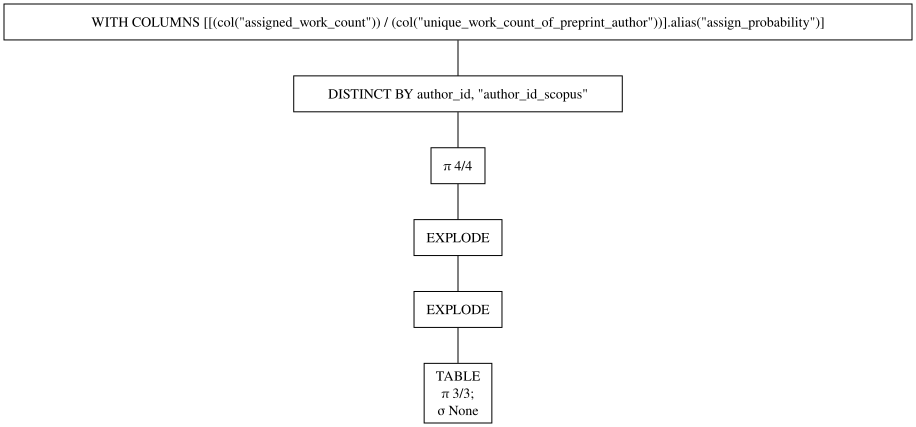

In [88]:
assigned_df = scopus_preprint_authors.lazy().explode("author_id").explode("author_id_scopus").select(
    [
        pl.col("author_id"),
        pl.col("author_id_scopus"),
        pl.count("doi").over("author_id").alias("unique_work_count_of_preprint_author"),
        pl.count("doi").over("author_id", "author_id_scopus").alias("assigned_work_count"),
    ]
).unique(["author_id", "author_id_scopus"]).with_columns(
    (pl.col("assigned_work_count") / pl.col("unique_work_count_of_preprint_author")).alias("assign_probability")
)
assigned_df.show_graph() 

In [97]:
confident = assigned_df.filter(
    pl.col("assign_probability") > 0.5
).collect()
confident.unique("author_id").height, confident.height

(9007, 9007)

In [98]:
confident.sort("unique_work_count_of_preprint_author", descending=True)

author_id,author_id_scopus,unique_work_count_of_preprint_author,assigned_work_count,assign_probability
str,i64,u32,u32,f64
"""A5024923217""",35569122000,1518,897,0.590909
"""A5062594909""",7402703729,1442,887,0.615118
"""A5052042350""",7006540445,989,525,0.530839
"""A5112960033""",7102787018,841,535,0.636147
"""A5015335031""",7006328027,808,413,0.511139
…,…,…,…,…
"""A5100325949""",57996183100,1,1,1.0
"""A5010242343""",36660824300,1,1,1.0
"""A5088197691""",36187854800,1,1,1.0


In [112]:
confident.head()

author_id,author_id_scopus,unique_work_count_of_preprint_author,assigned_work_count,assign_probability
str,i64,u32,u32,f64
"""A5046683626""",6507696354,9,7,0.777778
"""A5053927189""",56929679300,17,11,0.647059
"""A5106485922""",6603312310,1,1,1.0
"""A5011704225""",56235578600,34,22,0.647059
"""A5109382350""",7101944743,142,77,0.542254


In [ ]:
# matchした著者は30人のサンプルでは全て氏名が一致した。
# ただし、マッチした著者集団はサンプリングバイアスがありそう。概ね全作品に占めるプレプリントの割合が高い（平均はおそらく3倍から5倍のあたり）
# これがそれ以外の著者と比べても同様の結果なのか、は検証しておいた方がいい。
# 大学や出身国は概ね偏りなく取れている印象。分野はやや物理に偏っているかも。

sampled_authors = confident.sample(30).join(
        scopus_author_name,
        left_on="author_id_scopus",
        right_on="author_id",
        how="inner"
    ).select(
        [
            pl.col("author_id"),
            pl.col("author_id_scopus"),
            pl.col("name"),
            pl.col("unique_work_count_of_preprint_author").alias("journal_works"),
        ]
    )
sampled_authors.to_pandas()

,author_id,author_id_scopus,name,works
0,A5012368201,6602523831,Belot_Gordon,29
1,A5059172830,6602558164,Tadross_Ashraf Latif,31
2,A5085891249,6603153946,Develin_Mike,27
3,A5009793294,6603235446,Sheinman_Oleg K.,10
4,A5086528835,6603736296,Arada_Nadir,24
5,A5073407404,6603932276,Jafarpour_Farhad H.,42
6,A5109195684,7004105673,Quint_Jean-François,59
7,A5028420276,7005134453,Polonyi_Janos,113
8,A5044004929,7005819845,Colley_Susan Jane,23
9,A5089783007,7102858085,Weinberg_Erick J.,29


In [105]:
sampled_authors

author_id,author_id_scopus,unique_work_count_of_preprint_author,assigned_work_count,assign_probability
str,i64,u32,u32,f64
"""A5064874951""",6603062715,26,14,0.538462
"""A5033407556""",6701696919,75,44,0.586667
"""A5095459944""",58996088000,1,1,1.0
"""A5057422475""",35561603600,23,15,0.652174
"""A5024507034""",6602481820,29,16,0.551724
…,…,…,…,…
"""A5072532778""",57191914133,3,2,0.666667
"""A5033562631""",14421916000,30,17,0.566667
"""A5066632707""",56022653800,5,4,0.8


In [99]:
confident.write_parquet("./data/preprint_authors_scopusid_confident.parquet")

# calculate impact, hit ratio


In [5]:
import pandas as pd

In [115]:
openalex_scopusid_matching = pl.read_parquet("./data/preprint_authors_scopusid_confident.parquet").select(["author_id", "author_id_scopus"])
openalex_scopusid_matching

author_id,author_id_scopus
str,i64
"""A5046683626""",6507696354
"""A5053927189""",56929679300
"""A5106485922""",6603312310
"""A5011704225""",56235578600
"""A5109382350""",7101944743
…,…
"""A5065040776""",35823091700
"""A5040303059""",56720366400
"""A5001720154""",6603337551


In [121]:
author_works_journal = pl.read_parquet("./data/journals/author_works.parquet")
author_works_journal.head()

author_id,work_id
i64,list[i64]
35233311500,"[55849146354, 61849108681, … 85185397586]"
7003367364,[36806089]
57217451704,"[2442508686, 2442508686, 2442508686]"
35278292100,[67649444229]
56308458200,"[84938783018, 84944704736, … 85130087418]"


In [ ]:
works_detail = author_works_journal.filter(
        pl.col("author_id").is_in(openalex_scopusid_matching.get_column("author_id_scopus").to_numpy())
    ).explode("work_id").join(
        pl.read_parquet('./data/journals/c5.parquet'),
        on="work_id",
        how="inner"
    )

In [125]:
works_detail.head()
# left_on="author_id_scopus",
#         right_on="author_id",

author_id,work_id,c5
i64,i64,f64
7003620030,518,8.0
7003944467,561,30.0
6602150467,608,10.0
6602744820,608,10.0
8420583700,1188,2.0


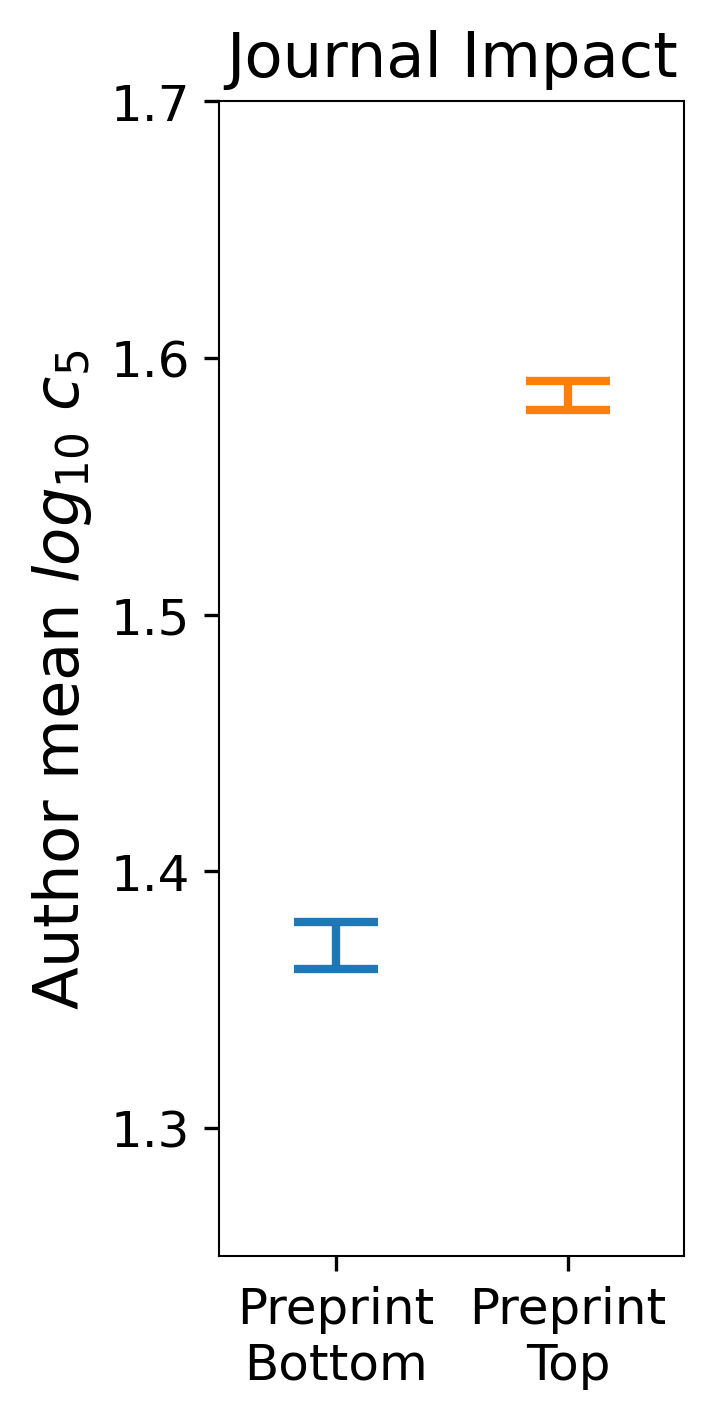

In [125]:
import numpy as np
import pandas as pd
from scipy.stats import mannwhitneyu, bootstrap

def median_func(data, axis=0):
    return np.median(data, axis=axis)

def bootstrapped_interval(data):
    res = bootstrap(
        (data,),
        median_func,
        confidence_level=0.95,
        n_resamples=1000,
        method='percentile'
    )
    median_val = np.median(data)
    ci_low = res.confidence_interval.low
    ci_high = res.confidence_interval.high
    
    return median_val - ci_low, ci_high - median_val

def draw_errorbar(medians, err):
    for i, e in enumerate(err):
        ax.errorbar(
            x = [i],
            y = [medians[i]],
            yerr=np.array([[e[0]], [e[1]]]),  # two-sided error bars
            fmt='none',  # 'o' for circular markers
            color=plt.rcParams['axes.prop_cycle'].by_key()['color'][i],
            linewidth=2,
            capsize=10,
            capthick=2,
        )
def confidence_interval(cols, labels, ax):
    # 対数変換（log1pを使って0も扱えるように）
    log_counts_all = np.log10(cols[0] +1)
    log_counts_unique = np.log10(cols[1] +1)
    
    # # データをまとめてプロット用に整形
    # df_plot = pd.DataFrame({
    #     colname[0]: log_counts_all,
    #     colname[1]: log_counts_unique
    # })
    
    # 箱ひげ図の描画
    err = [bootstrapped_interval(log_counts_all), bootstrapped_interval(log_counts_unique)]
    draw_errorbar([np.median(log_counts_all), np.median(log_counts_unique)], err)
    ax.set_xticks([0, 1], ['Preprint\nBottom', 'Preprint\nTop'])
    ax.set_xlim(-0.5, 1.5)
    ax.set_ylabel(labels['ylabel'])
    ax.set_title(labels['title'])
    # ax.boxplot(
    #     [log_counts_all, log_counts_unique],
    #     widths=0.5,
    #     labels=("Preprint\nBottom", "Preprint\nTop"),
    #     showmeans=True,
    #     meanline=True,
    #     boxprops=dict(color='black'),
    #     medianprops=dict(color='red'),
    #     meanprops=dict(color='blue')
    # )
    # sns.violinplot(data=df_plot)
    
    
    # Mann-Whitney U検定
    stat, p = mannwhitneyu(log_counts_all, log_counts_unique, alternative='two-sided')
    
    return stat, p 

fig, ax = plt.subplots(1,1, figsize=(2,5))
confidence_interval(
    (scopus_work[scopus_work['tier']=='middle']['c5'].dropna(),
    scopus_work[scopus_work['tier']=='top']['c5'].dropna()),
    labels={'ylabel':'Author mean $log_{10}$ $c_{5}$', 'title':'Journal Impact'},
    ax=ax
)
ax.set_ylim(1.25, 1.7)
ax.set_yticks([1.3, 1.4, 1.5, 1.6, 1.7])

(1.8, 2.25)

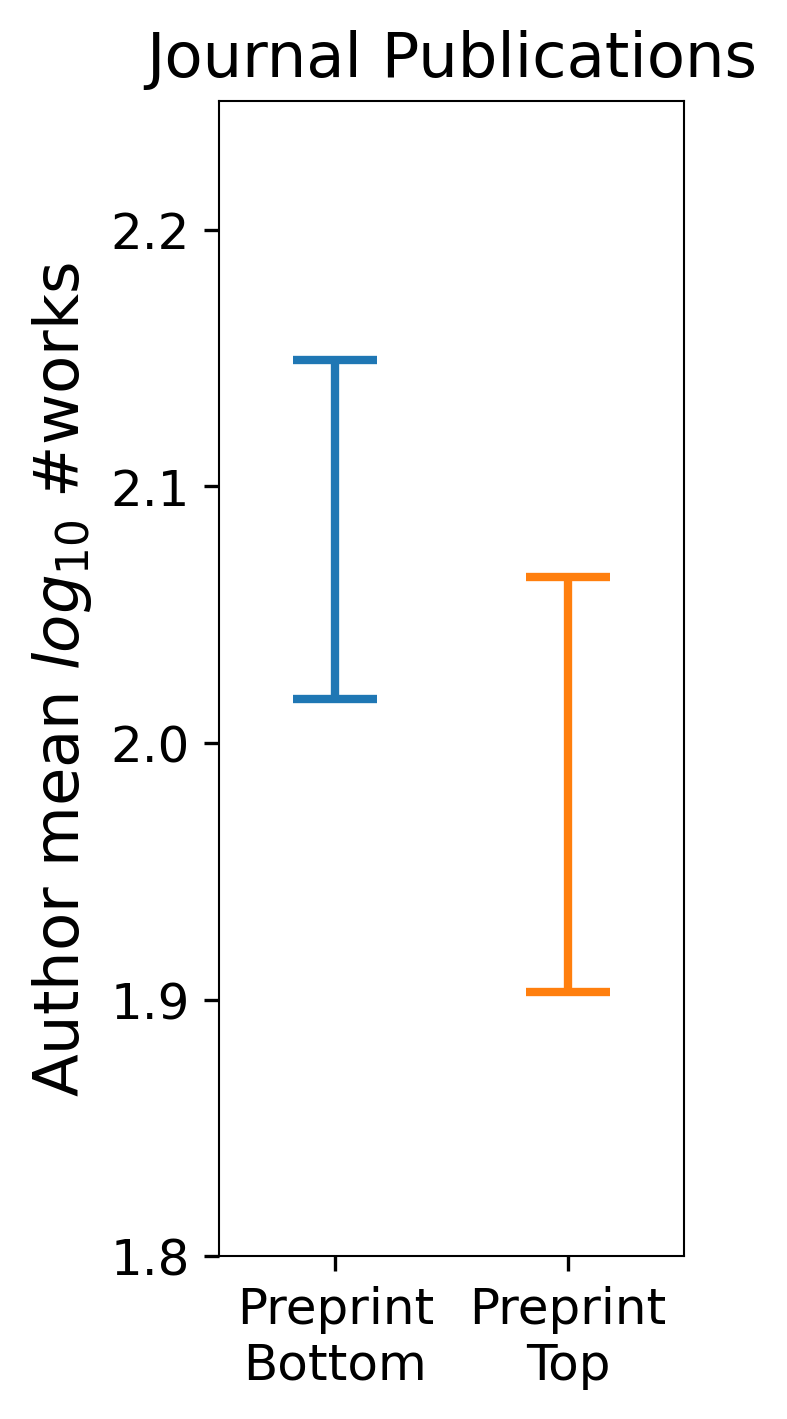

In [124]:
fig, ax = plt.subplots(1,1, figsize=(2,5))
confidence_interval(
    (
        scopus_work[scopus_work['tier']=='middle'].dropna(subset='c5').groupby('authids')['eid'].size(),
        scopus_work[scopus_work['tier']=='top'].dropna(subset='c5').groupby('authids')['eid'].size()
    ),
    labels={'ylabel':'Author mean $log_{10}$ #works', 'title':'Journal Publications'},
    ax=ax
)

ax.set_yticks([1.8, 1.9, 2.0, 2.1, 2.2])
ax.set_ylim(1.8, 2.25)

# hit ratio


In [ ]:
citation_normalized_percentile_df  = pl.read_ndjson(openalex_dir + "works/citation_normalized_percentile.jsonl.gz").select(
    [
    pl.col("work_id"),
    pl.col("citation_normalized_percentile").struct["is_in_top_1_percent"]
    ]
)
citation_normalized_percentile_df.head()

work_id,citation_normalized_percentile
str,struct[3]
"""W2440680649""","{0.647615,false,false}"
"""W2089131837""","{0.456788,false,false}"
"""W1489721217""","{0.0,false,false}"
"""W3023614225""","{0.560606,false,false}"
"""W107598049""","{0.0,false,false}"


In [178]:
citation_normalized_percentile_df

work_id,is_in_top_1_percent
str,bool
"""W2440680649""",false
"""W2089131837""",false
"""W1489721217""",false
"""W3023614225""",false
"""W107598049""",false
…,…
"""W4408162233""",false
"""W4408162240""",false
"""W4408162243""",false


# preprint author work count distribution

In [ ]:
openalex_scopusid_matching

work_id,author_id
str,list[str]
"""W4254804269""","[""A5064285042""]"
"""W4214486962""","[""A5064837938""]"
"""W1534361483""","[""A5105506287""]"
"""W3204041617""","[""A5101031318""]"
"""W4210515815""","[""A5046168805""]"
…,…
"""W4408162233""","[""A5028434739"", ""A5100674571"", … ""A5068127098""]"
"""W4408162240""","[""A5056294946"", ""A5054097318"", … ""A5108685599""]"
"""W4408162243""","[""A5080810870"", ""A5107138677"", … ""A5014202722""]"


In [ ]:
import matplotlib.pyplot as plt
work_count_df = authors_df.explode("author_id").with_columns(
    pl.col("work_id").is_in(oa.get_column("work_id").to_numpy()).alias("is_preprint")
).select(
    [
        "author_id",
        "is_preprint",
        pl.count("work_id").over(["author_id", "is_preprint"]).alias("works_count"),
    ]
).pivot(
    index="author_id",
    on="is_preprint",
    values="works_count",
    aggregate_function="first"
).drop_nulls()

work_count_df

author_id,false,true
str,u32,u32
"""A5000384936""",14,2
"""A5038674741""",41,1
"""A5012745879""",23,3
"""A5087567618""",36,1
"""A5004089149""",70,1
…,…,…
"""A5052474151""",1,2
"""A5042106606""",1,1
"""A5110242476""",1,1


In [164]:
work_count_filtered_df = work_count_df.filter(
    pl.col("author_id").is_in(
        confident.get_column("author_id").to_numpy()
    )
)

In [162]:
scopus_preprint_authors

author_id,doi,author_id_scopus
list[str],str,list[i64]
"[""A5000748782"", ""A5059139821""]","""10.1063/1.1285965""","[7006050637, 6603697521, 6602703231]"
"[""A5039140400"", ""A5037518207""]","""10.1093/mnras/289.4.766""","[7403462856, 7403462856, … 7007017995]"
"[""A5042980375"", ""A5023340072""]","""10.1063/1.340894""","[7103402443, 7102327337, 7005473666]"
"[""A5028283617"", ""A5023808431""]","""10.1016/0168-9002(95)00492-0""","[22996703700, 7006630334, … 11041540000]"
"[""A5067023265"", ""A5071615340""]","""10.1088/0953-8984/7/48/006""","[7006330305, 7004847903, … 7005665661]"
…,…,…
"[""A5101816534""]","""10.1145/3652628.3652742""","[58149415300, 55341427500, … 59151094200]"
"[""A5050053428""]","""10.1007/978-3-031-29769-4_5""","[6603502644, 55820203300, 55673087000]"
"[""A5072563444""]","""10.1145/3639856.3639920""","[7402215680, 57203638167, … 58093997000]"


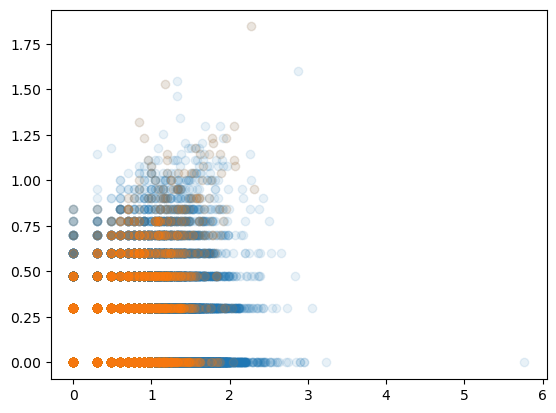

In [168]:
import numpy as np
plt.scatter(
    np.log10(work_count_df.get_column("false").to_numpy()),
    np.log10(work_count_df.get_column("true").to_numpy()),
    alpha=0.1
)

plt.scatter(
    np.log10(work_count_filtered_df.get_column("false").to_numpy()),
    np.log10(work_count_filtered_df.get_column("true").to_numpy()),
    alpha=0.1
)

# author mean fwci percentile for journal and preprint

In [170]:
author_works_preprint = authors_df.explode("author_id").group_by("author_id").agg(
    "work_id"
)
author_works_preprint.head()

author_id,work_id
str,list[str]
"""A5040804123""","[""W3016953816"", ""W3045227331""]"
"""A5054246515""","[""W288853576"", ""W280878724""]"
"""A5080117322""","[""W1892432334""]"
"""A5028018344""","[""W3101674856""]"
"""A5034692077""","[""W2060407744"", ""W2085860949""]"


In [ ]:
author_works_preprint.write_parquet(openalex_dir + "works/authors_works.parquet")

In [199]:
c_normalized_percentile_df  = pl.read_ndjson(openalex_dir + "works/citation_normalized_percentile.jsonl.gz").select(
    [
    pl.col("work_id"),
    pl.col("citation_normalized_percentile").struct["value"]
    ]
)
c_normalized_percentile_df.head()

work_id,value
str,f64
"""W2440680649""",0.647615
"""W2089131837""",0.456788
"""W1489721217""",0.0
"""W3023614225""",0.560606
"""W107598049""",0.0


In [ ]:
# fwci = pl.read_ndjson(openalex_dir + "works/fwci.jsonl.gz") #.filter(
#     pl.col("fwci")<pl.col("fwci").quantile(0.99),
#     pl.col("fwci")>pl.col("fwci").quantile(0.01),
# )

In [ ]:
author_percentile = author_works_preprint.filter(
    pl.col("author_id").is_in(
        confident.get_column("author_id").to_numpy()
    )
).explode("work_id").join(
    c_normalized_percentile_df,
    on="work_id",
    how="inner"
).with_columns(
    pl.col("work_id").is_in(oa.get_column("work_id").to_numpy()).alias("is_preprint")
).select(
    "author_id",
    "is_preprint",
    pl.mean("value").over(["author_id", "is_preprint"]).alias("mean_fwci"),
).pivot(
    index="author_id",
    on="is_preprint",
    values="mean_fwci",
    aggregate_function="first"
).drop_nulls()
author_percentile.head()

author_id,false,true
str,f64,f64
"""A5090203774""",0.223258,0.84716
"""A5001361123""",0.599136,0.274727
"""A5047494640""",0.18992,0.43832
"""A5039463977""",0.19373,0.0
"""A5077357206""",0.213686,0.380021


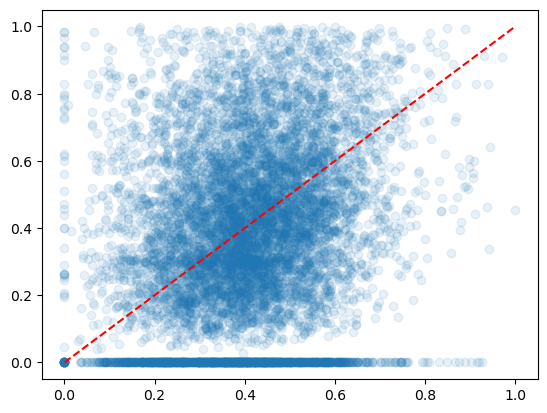

In [207]:
plt.scatter(author_percentile.get_column("false"), author_percentile.get_column("true"),alpha=0.1)
plt.plot([0,1], [0,1], color='red', linestyle='--')
# .unique(["author_id", "is_preprint"])

# Author mean FWCI


In [1]:
import polars as pl
from constant import openalex_dir

c_fwci_df = pl.scan_ndjson(openalex_dir + "works/fwci.jsonl.gz")
oa = pl.concat([
    pl.read_parquet("./data/biorxiv/biorxiv_citation_detail.parquet").with_columns(pl.lit("biorxiv").alias("server")),
    pl.read_parquet("./data/arxiv/arxiv_citation_detail.parquet").with_columns(pl.lit("arxiv").alias("server"))
])
author_df = pl.scan_ndjson(openalex_dir + "works/author_id.jsonl.gz")
c_fwci_df.head()

In [4]:
# c_fwci_df.height, c_fwci_df.drop_nulls("fwci").height

In [2]:
fwci_df = c_fwci_df.with_columns(
    pl.col("work_id").is_in(oa.get_column("work_id").to_numpy()).alias("is_preprint")
)
# .with_columns(
#     pl.quantile("fwci", 0.99).over("is_preprint").alias("fwci_99_quantile"),
#     pl.quantile("fwci", 0.01).over("is_preprint").alias("fwci_1_quantile")
# ).filter(
#     pl.col("fwci") < pl.col("fwci_99_quantile"),
#     pl.col("fwci") > pl.col("fwci_1_quantile")
# )

In [3]:
author_df_ = author_df.filter(
    pl.col("author_id").list.len().is_between(1, 10)
).explode("author_id").collect()

author_df_.height

567764602

In [4]:
preprint_author = author_df_.with_columns(
    pl.col("work_id").is_in(oa.get_column("work_id").to_numpy()).alias("is_preprint")
).group_by(["author_id", "is_preprint"]).agg(
    pl.len().alias("count")
).pivot(
    values="count", 
    index="author_id", 
    on="is_preprint"
).drop_nulls()

preprint_author

author_id,false,true
str,u32,u32
"""A5067981515""",2,2
"""A5103163616""",66,1
"""A5008377928""",7,1
"""A5101451200""",9,1
"""A5064642742""",18,6
…,…,…
"""A5078897737""",177,3
"""A5029018491""",48,1
"""A5010935187""",93,15


In [6]:
author_fwcis_df = author_df_.filter(
    pl.col("author_id").is_in(
        preprint_author.get_column("author_id").to_numpy()
    )
).join(
    c_fwci_df.collect(),
    on="work_id",
    how="inner"
).with_columns(
    pl.col("work_id").is_in(oa.get_column("work_id").to_numpy()).alias("is_preprint")
)

author_fwcis_df

work_id,author_id,fwci,is_preprint
str,str,f64,bool
"""W1517480089""","""A5012992365""",0.0,false
"""W4250832609""","""A5001979226""",0.0,false
"""W2340602555""","""A5034853815""",0.0,false
"""W1492575150""","""A5031463098""",0.0,false
"""W3110276681""","""A5068447187""",0.0,false
…,…,…,…
"""W4408162220""","""A5057672960""",0.0,false
"""W4408162225""","""A5063570609""",0.0,false
"""W4408162233""","""A5100674571""",0.0,false


In [ ]:
# author_fields = author_fwcis_df.join(oa, on="work_id", how="inner").group_by("author_id").agg(
#     pl.col("primary_field").mode()
# ).select(
#     [
#         "author_id",
#         pl.col("primary_field").list.first().alias("primary_field_of_author")
#     ]
# )
# author_fields

author_id,primary_field_of_author
str,str
"""A5058364616""","""q-bio"""
"""A5004592971""","""math"""
"""A5060535118""","""cs"""
"""A5005586574""","""cond-mat"""
"""A5042676951""","""cs"""
…,…
"""A5063398043""","""cs"""
"""A5039043184""","""cs"""
"""A5086787265""","""cs"""


In [ ]:
# author_fwcis_df.filter(is_preprint=True).sort("fwci", descending=False)

work_id,author_id,fwci,is_preprint,fwci_99_quantile,fwci_1_quantile
str,str,f64,bool,f64,f64
"""W2798931691""","""A5043297666""",0.012,true,8.209,0.0
"""W2798931691""","""A5081440129""",0.012,true,8.209,0.0
"""W2798931691""","""A5091882891""",0.012,true,8.209,0.0
"""W2798931691""","""A5053035791""",0.012,true,8.209,0.0
"""W2955835258""","""A5025815850""",0.018,true,8.209,0.0
…,…,…,…,…,…
"""W2964018346""","""A5024072566""",8.192,true,8.209,0.0
"""W1518461880""","""A5040311844""",8.196,true,8.209,0.0
"""W1518461880""","""A5066238431""",8.196,true,8.209,0.0


In [ ]:
# author_mean_fwci.select(
#     "primary_field_of_author",
#     pl.count("author_id").over("primary_field_of_author").alias("count")
# ).unique("primary_field_of_author").sort("count", descending=True)

primary_field_of_author,count
str,u32
"""cs""",8866
"""math""",4814
"""cond-mat""",4498
"""hep""",3222
"""physics""",2184
…,…
"""molcel""",149
"""eess""",146
"""biomed""",141


In [41]:
num_tiers = 2
author_mean_fwci = author_fwcis_df.group_by("author_id","is_preprint").agg(
    pl.mean("fwci").alias("mean_fwci"),
    pl.count("fwci").alias("count")
).pivot(
    values=["mean_fwci","count"], 
    index="author_id", 
    on="is_preprint"
).drop_nulls().filter(
    pl.col("count_true")>0,
    pl.col("count_false")>0,
    pl.col("mean_fwci_false")>0,
).with_columns(
    (pl.col("mean_fwci_true") / pl.col("mean_fwci_false")).alias("mean_fwci_ratio"),
)

# .filter(
#     pl.col("mean_fwci_ratio").is_not_nan()
# )
# .join(
#     author_fields, 
#     on="author_id", 
#     how="inner"
# )

fwci_tiers_df = author_mean_fwci.with_columns(
    pl.col("mean_fwci_false").qcut(quantiles=[0.9], labels=[str(i) for i in range(num_tiers)]).alias("journal_impact_tier"),
).group_by("journal_impact_tier").agg(
    [
        pl.count("author_id").alias("author_count"),
        pl.col("mean_fwci_false"),
        pl.col("mean_fwci_true"),
        pl.col("mean_fwci_ratio"),
        pl.col("count_true"),
        pl.col("count_false")
    ]
)


In [25]:
author_mean_fwci.max()

author_id,mean_fwci_false,mean_fwci_true,count_false,count_true,mean_fwci_ratio
str,f64,f64,u32,u32,f64
"""A5116636560""",29.737224,32.03325,4592,34,14.024595


In [ ]:
author_mean_fwci. sort("mean_fwci_false", descending=False).head(30000).tail(100)

author_id,mean_fwci_false,mean_fwci_true,count_false,count_true,mean_fwci_ratio
str,f64,f64,u32,u32,f64
"""A5088807601""",1.406523,0.173,44,1,0.122998
"""A5087175088""",1.406587,0.0,126,1,0.0
"""A5058862418""",1.406616,0.145,73,1,0.103084
"""A5009261745""",1.406623,0.12,53,1,0.085311
"""A5000788211""",1.406721,0.584,43,1,0.41515
…,…,…,…,…,…
"""A5007709254""",1.410125,0.09,16,1,0.063824
"""A5100605273""",1.410222,0.153,230,1,0.108494
"""A5100333738""",1.410273,1.207,604,1,0.855863


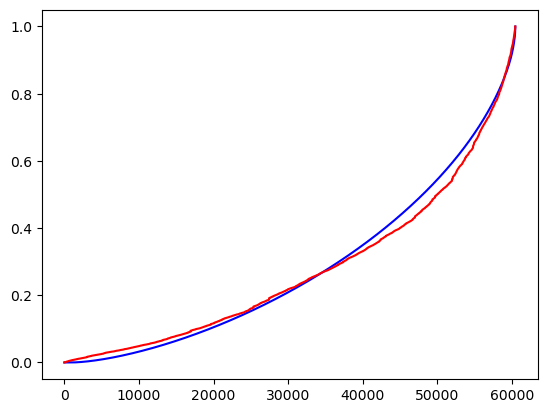

In [259]:
mean_fwci_journal = author_mean_fwci.sort("mean_fwci_false", descending=False).get_column("mean_fwci_false").to_numpy()
mean_fwci_preprint = author_mean_fwci.sort("mean_fwci_false", descending=False).get_column("mean_fwci_true").to_numpy()
plt.plot(mean_fwci_journal.cumsum() / mean_fwci_journal.sum(), color='blue')
plt.plot(mean_fwci_preprint.cumsum() / mean_fwci_preprint.sum(), color='red')

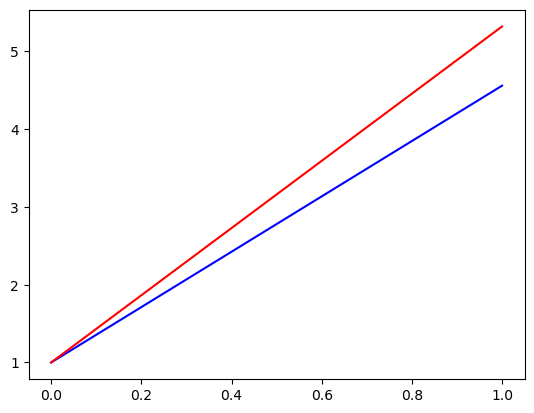

In [250]:
num_tiers = 2
fwci_tiers_mean = author_mean_fwci.with_columns(
    pl.col("mean_fwci_false").qcut(quantiles=[0.9], labels=[str(i) for i in range(num_tiers)]).alias("journal_impact_tier"),
).group_by("journal_impact_tier").agg(
    [
        pl.count("author_id").alias("author_count"),
        pl.mean("mean_fwci_false"),
        pl.mean("mean_fwci_true"),
        # pl.col("count_true"),
        # pl.col("count_false")
    ]
)

fwci_tiers_journal_normalized = fwci_tiers_mean.get_column("mean_fwci_false").to_numpy() / fwci_tiers_mean.get_column("mean_fwci_false").to_numpy()[0]
fwci_tiers_preprint_normalized = fwci_tiers_mean.get_column("mean_fwci_true").to_numpy() / fwci_tiers_mean.get_column("mean_fwci_true").to_numpy()[0]
plt.plot([i for i in range(num_tiers)], fwci_tiers_journal_normalized, color='blue')
plt.plot([i for i in range(num_tiers)], fwci_tiers_preprint_normalized, color='red')

In [234]:
fwci_tiers_journal_normalized, fwci_tiers_preprint_normalized

(array([0.42805757, 1.        , 2.60409257]),
 array([0.54765628, 1.        , 3.0719429 ]))

In [42]:
import numpy as np
from collections import defaultdict
from scipy.stats import mannwhitneyu, bootstrap

def agg_func(data):
    return np.mean(data)

def bootstrapped_interval(data):
    res = bootstrap(
        (data,),
        agg_func,
        confidence_level=0.95,
        n_resamples=1000,
        method='percentile'
    )
    median_val = agg_func(data)
    ci_low = res.confidence_interval.low
    ci_high = res.confidence_interval.high
    
    return median_val, (median_val - ci_low , ci_high - median_val)

fwci_tiers = defaultdict(dict)
for tier in fwci_tiers_df.get_column("journal_impact_tier").unique().to_list():
    for col in ["mean_fwci_false", "mean_fwci_true", "mean_fwci_ratio", "count_false", "count_true"]:
        # print(f"{tier} : {fwci_tiers_df.filter(pl.col('journal_impact_tier') == tier).get_column('author_count').sum()}")
        fwci_tiers[tier][col] = bootstrapped_interval(fwci_tiers_df.filter(pl.col("journal_impact_tier") == tier)[col][0].to_numpy())
fwci_tiers

defaultdict(dict,
            {'0': {'mean_fwci_false': (1.4547486845113768,
               (0.007313058949549811, 0.007059419726746841)),
              'mean_fwci_true': (0.49044899873140013,
               (0.022533180513465978, 0.02421604239312003)),
              'mean_fwci_ratio': (0.39271980321895555,
               (0.018028536421507813, 0.02229602469269376)),
              'count_false': (101.2184023889511,
               (1.3036310190369562, 1.4295926651735726)),
              'count_true': (1.369223590892124,
               (0.008586226203807446, 0.008439716312056644))},
             '1': {'mean_fwci_false': (6.544890781581336,
               (0.16422169991985935, 0.19533303878956243)),
              'mean_fwci_true': (2.610497665560566,
               (0.1712078488346216, 0.19505577626691473)),
              'mean_fwci_ratio': (0.4284117777999565,
               (0.03468026949432729, 0.038254420115475196)),
              'count_false': (115.57591535102452,
               (4.

In [9]:
from matplotlib import pyplot as plt
import numpy as np
import scienceplots
plt.rcParams['figure.dpi'] = 300
plt.style.use(['nature']) # start with ['science'] then ['nature']. use 'notebook', 'no-latex', 'cjk-jp-font' if needed.
plt.rc('axes', titlesize=15, labelsize=15)      # Title font size
plt.rc('xtick', labelsize=12)     # X-axis tick font size
plt.rc('ytick', labelsize=12)     # Y-axis tick font size
plt.rc('legend', fontsize=13)     # Legend font sizplt

print(plt.rcParams['axes.prop_cycle'].by_key()['color'])

['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b', '#e377c2', '#7f7f7f', '#bcbd22', '#17becf']


In [ ]:
fwci_tiers[]
# for i in ["false","true"]:
#     x = [j for j in range(num_tiers)]
#     y = np.array([fwci_tiers[str(j)][f"mean_fwci_{i}"][0] for j in range(num_tiers)]) / fwci_tiers["0"][f"mean_fwci_{i}"][0]
#     yerr = np.array([ [fwci_tiers[str(j)][f"mean_fwci_{i}"][1][0]], [fwci_tiers[str(j)][f"mean_fwci_{i}"][1][0]] for j in range(num_tiers)]) / fwci_tiers["0"][f"mean_fwci_{i}"][0]
#     ax.errorbar(x=x, y=y, yerr=yerr, fmt='o', label=f"Tier {i}", markersize=3 ,markeredgecolor=colors[i], color='w', ecolor=colors[i], linewidth=2,
#             capsize=10,
#             capthick=2)
#     ax.plot(x, y, color=colors[i], linestyle='--')
#     ax.set_xticks(x, labels=["Journal\nAverage", "Journal\nTop"])
#     ax.set_xlim(-0.5, num_tiers-0.5)
# ax.set_ylabel("Impact on\n Preprint and Journal")

In [56]:
fig, ax = plt.subplots(1, 1, figsize=(2,4))
# colors = {v: plt.rcParams['axes.prop_cycle'].by_key()['color'][i] for i,v in enumerate(["false","true"])}
colors = {"false":"gray", "true":"red"}

for i in ["false","true"]:
    x = [j for j in range(num_tiers)]
    y = np.array([fwci_tiers[str(j)][f"mean_fwci_{i}"][0] for j in range(num_tiers)]) / fwci_tiers["0"][f"mean_fwci_{i}"][0]
    yerr = np.array([ [fwci_tiers[str(j)][f"mean_fwci_{i}"][1][0]], [fwci_tiers[str(j)][f"mean_fwci_{i}"][1][0]] for j in range(num_tiers)]) / fwci_tiers["0"][f"mean_fwci_{i}"][0]
    ax.errorbar(x=x, y=y, yerr=yerr, fmt='o', label=f"Tier {i}", markersize=3 ,markeredgecolor=colors[i], color='w', ecolor=colors[i], linewidth=2,
            capsize=10,
            capthick=2)
    ax.plot(x, y, color=colors[i], linestyle='--')
    ax.set_xticks(x, labels=["Journal\nAverage", "Journal\nTop"])
    ax.set_xlim(-0.5, num_tiers-0.5)

ax.set_xlabel("Impact on\n Preprint and Journal")

SyntaxError: did you forget parentheses around the comprehension target? (748578501.py, line 8)

Text(0.5, 0, 'Journal Prestige')

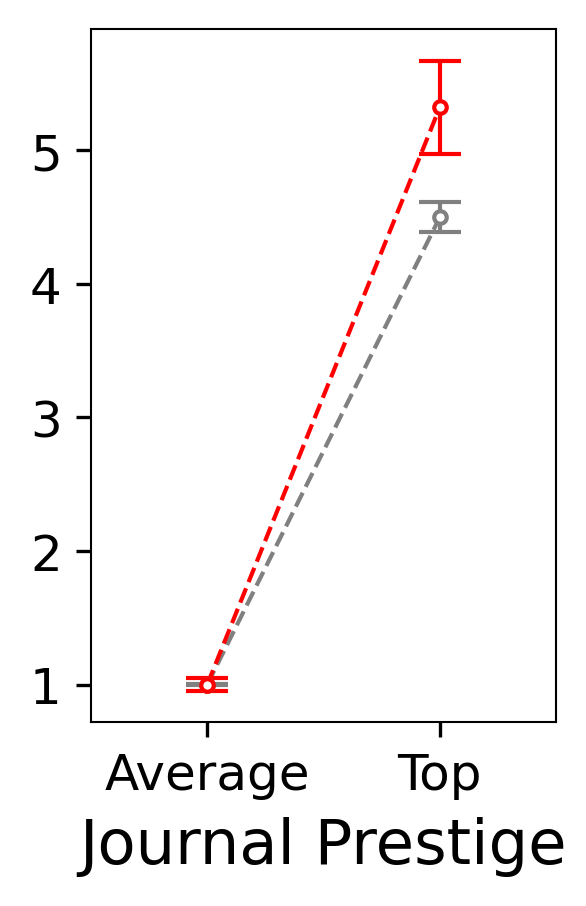

In [57]:
fig, ax = plt.subplots(1, 1, figsize=(2,3))
# colors = {v: plt.rcParams['axes.prop_cycle'].by_key()['color'][i] for i,v in enumerate(["false","true"])}
colors = {"false":"gray", "true":"red"}

for i in ["false","true"]:
    x = [j for j in range(num_tiers)]
    y = np.array([fwci_tiers[str(j)][f"mean_fwci_{i}"][0] for j in range(num_tiers)]) / fwci_tiers["0"][f"mean_fwci_{i}"][0]
    yerr = np.array([ [fwci_tiers[str(j)][f"mean_fwci_{i}"][1][0] for j in range(num_tiers)], [fwci_tiers[str(j)][f"mean_fwci_{i}"][1][0] for j in range(num_tiers)]]) / fwci_tiers["0"][f"mean_fwci_{i}"][0]
    ax.errorbar(x=x, y=y, yerr=yerr, fmt='o', label=f"Tier {i}", markersize=3 ,markeredgecolor=colors[i], color='w', ecolor=colors[i], linewidth=1,
            capsize=5,
            capthick=1)
    ax.plot(x, y, color=colors[i], linestyle='--', linewidth=1)
    ax.set_xticks(x, labels=["Average", "Top"])
    ax.set_xlim(-0.5, num_tiers-0.5)
ax.set_xlabel("Journal Prestige")
# ax.legend
# ax.set_ylabel("Impact on\n Preprint and Journal")

In [63]:
fwci_tiers["0"][f"mean_fwci_{i}"][0]

1.4547486845113768

In [62]:
i = "false"
np.array([ [fwci_tiers[str(j)][f"count_{i}"][1][0] for j in range(num_tiers)], [fwci_tiers[str(j)][f"count_{i}"][1][1] for j in range(num_tiers)]]) / fwci_tiers["0"][f"mean_fwci_{i}"][0]

array([[0.89612112, 2.84263298],
       [0.98270765, 2.7254343 ]])

In [60]:
fwci_tiers

defaultdict(dict,
            {'0': {'mean_fwci_false': (1.4547486845113768,
               (0.007313058949549811, 0.007059419726746841)),
              'mean_fwci_true': (0.49044899873140013,
               (0.022533180513465978, 0.02421604239312003)),
              'mean_fwci_ratio': (0.39271980321895555,
               (0.018028536421507813, 0.02229602469269376)),
              'count_false': (101.2184023889511,
               (1.3036310190369562, 1.4295926651735726)),
              'count_true': (1.369223590892124,
               (0.008586226203807446, 0.008439716312056644))},
             '1': {'mean_fwci_false': (6.544890781581336,
               (0.16422169991985935, 0.19533303878956243)),
              'mean_fwci_true': (2.610497665560566,
               (0.1712078488346216, 0.19505577626691473)),
              'mean_fwci_ratio': (0.4284117777999565,
               (0.03468026949432729, 0.038254420115475196)),
              'count_false': (115.57591535102452,
               (4.

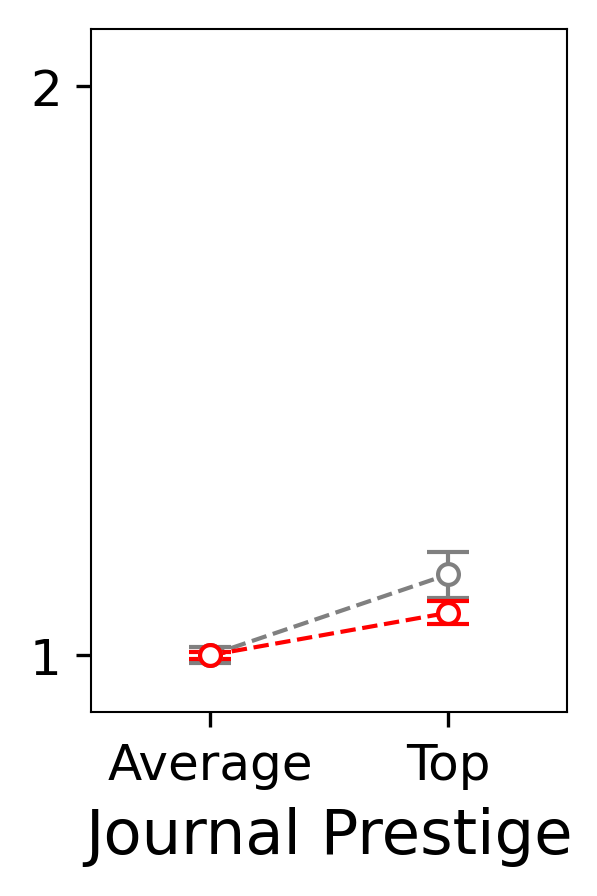

In [73]:
fig, ax = plt.subplots(1, 1, figsize=(2,3))
# colors = {v: plt.rcParams['axes.prop_cycle'].by_key()['color'][i] for i,v in enumerate(["false","true"])}
colors = {"false":"gray", "true":"red"}

for i in ["false","true"]:
    x = [j for j in range(num_tiers)]
    y = np.array([fwci_tiers[str(j)][f"count_{i}"][0] for j in range(num_tiers)]) / fwci_tiers["0"][f"count_{i}"][0]
    yerr = np.array([ [fwci_tiers[str(j)][f"count_{i}"][1][0] for j in range(num_tiers)], [fwci_tiers[str(j)][f"count_{i}"][1][1] for j in range(num_tiers)]]) / fwci_tiers["0"][f"count_{i}"][0]
    ax.errorbar(x=x, y=y, yerr=yerr, fmt='o', label=f"Tier {i}", markersize=5 ,markeredgecolor=colors[i], color='w', ecolor=colors[i], linewidth=1,
            capsize=5,
            capthick=1)
    ax.plot(x, y, color=colors[i], linestyle='--', linewidth=1)
    ax.set_xticks(x, labels=["Average", "Top"])
    ax.set_xlim(-0.5, num_tiers-0.5)
ax.set_xlabel("Journal Prestige")
ax.set_ylim(0.9,2.1)
ax.set_yticks([1, 2])
# ax.legend
# ax.set_ylabel("Impact on\n Preprint and Journal")
fig.tight_layout()

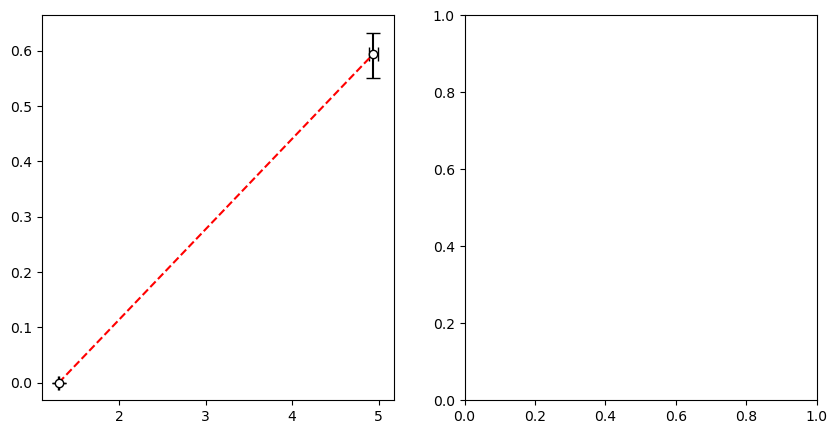

In [ ]:
i = 0
fig, ax = plt.subplots(1, 2, figsize=(10, 5))

for tier, values in fwci_tiers.items():
    i += 1
    ax[0].errorbar(
        x=values["mean_fwci_false"][0], 
        y=values["mean_fwci_true"][0], 
        xerr=[[values["mean_fwci_false"][1][0]], [values["mean_fwci_false"][1][1]] ], 
        yerr=[[values["mean_fwci_true"][1][0]], [values["mean_fwci_true"][1][1]] ], 
        fmt='o', 
        label=f"Tier {tier}",
        capsize=5,
        markeredgecolor = "black", color='w',ecolor='black'
    )
    
ax[0].plot(
    [
        fwci_tiers["0"]["mean_fwci_false"][0],
        fwci_tiers[str(num_tiers-1)]["mean_fwci_false"][0]
        ],
        [
            fwci_tiers["0"]["mean_fwci_true"][0], 
            fwci_tiers[str(num_tiers-1)]["mean_fwci_true"][0], 
    ], color='red', linestyle='--')
    # ax[1].errorbar(
    #     x=values["count_false"][0], 
    #     y=values["count_true"][0], 
    #     xerr=[[values["count_false"][1][0]], [values["count_false"][1][1]] ], 
    #     yerr=[[values["count_true"][1][0]], [values["count_true"][1][1]] ], 
    #     fmt='o', 
    #     label=f"Tier {tier}",
    #     capsize=5,
    #     markeredgecolor = "black", color='w',ecolor='black'
    # )


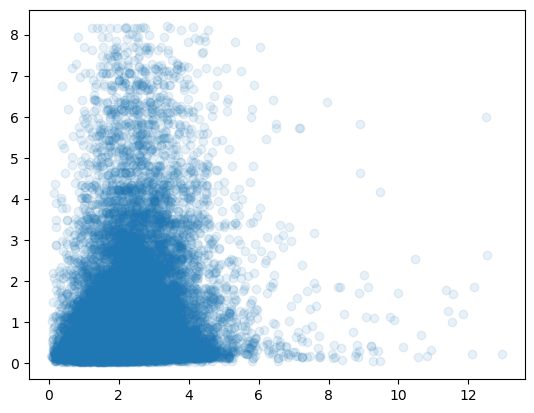

In [196]:
import matplotlib.pyplot as plt

plt.scatter(
    author_mean_fwci.get_column("mean_fwci_false"),
    author_mean_fwci.get_column("mean_fwci_true"),
    alpha=0.1
)
